<a href="https://colab.research.google.com/github/apoorwa46/ML-Project/blob/main/AQI_PBL_Review_3_Ensemble_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AQI Prediction Using Ensemble Learning — PBL Review 3

**Review 3 scope only:** Problem identification and dataset selection, ensemble-learning implementation, comparative performance analysis, and result interpretation.

Dataset: `city_day.csv` (city-wise daily air-quality observations).  
Target: numerical `AQI` (supervised regression).

This notebook intentionally excludes the previous review's K-Means and Gaussian HMM sections.


## 1. Problem Identification

Air quality is influenced by several pollutants, including PM2.5, PM10, NO₂, NOx, NH₃, CO, SO₂ and O₃. This project estimates numerical AQI from pollutant measurements and contextual city/date information.

**Problem statement:** Build a supervised regression system that predicts AQI from recorded pollutant concentrations.

**Why ensemble learning?** Ensemble methods combine multiple learners to improve predictive performance, reduce model variance, and capture nonlinear relationships.


## 2. Dataset Selection

**Selected dataset:** `city_day.csv` — city-wise daily air-quality observations for Indian cities.

Expected columns include `City`, `Date`, pollutant measurements (such as `PM2.5`, `PM10`, `NO2`, `CO`, `SO2`, `O3`) and target `AQI`. `AQI_Bucket` may also be present, but it is not used as an input feature.

**Justification:** The dataset contains real-world pollutant measurements and corresponding numerical AQI values across cities and dates, making it suitable for supervised AQI regression.


In [1]:
# Upload the CSV in Google Colab
from google.colab import files
uploaded = files.upload()

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_name = next((f for f in uploaded if f.lower().endswith(".csv")), None)
if csv_name is None:
    raise ValueError("Upload the city_day.csv file.")
df = pd.read_csv(io.BytesIO(uploaded[csv_name]))
df.columns = df.columns.str.strip()

print("Dataset:", csv_name)
print("Shape:", df.shape)
display(df.head())
print(df.info())
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())


Saving city_day.csv to city_day.csv
Dataset: city_day.csv
Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB
None


,Missing values
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022


Duplicate rows: 0


## 3. Data Preparation

We parse dates, remove rows without a valid AQI/date, remove duplicates, and derive calendar features. Available pollutant columns are detected from the uploaded dataset. The target `AQI` and category `AQI_Bucket` are never used as predictors, avoiding target leakage.


Pollutant features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Rows available: 24850


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,Year,Month,Day,DayOfYear,City,AQI
0,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,2015,1,1,1,Delhi,472.0
1,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,2015,1,2,2,Delhi,454.0
2,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,2015,1,3,3,Delhi,143.0
3,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,2015,1,4,4,Delhi,319.0
4,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,2015,1,5,5,Delhi,325.0


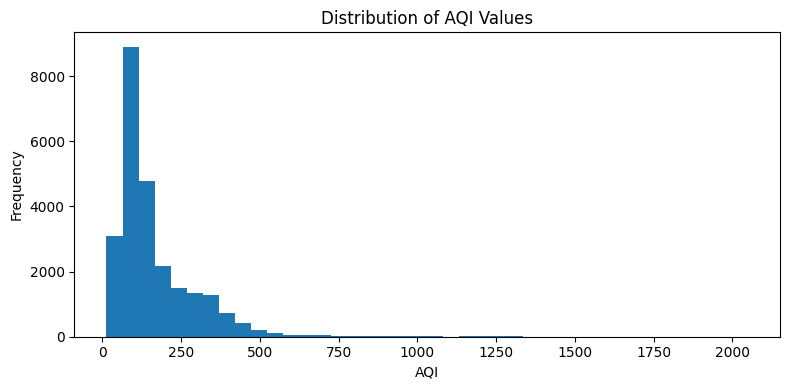

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["AQI"] = pd.to_numeric(df["AQI"], errors="coerce")
df = df.dropna(subset=["Date", "AQI"]).drop_duplicates().copy()

candidate_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]
pollutants = [c for c in candidate_pollutants if c in df.columns]
if not pollutants:
    raise ValueError("No expected pollutant columns found. Check CSV column names.")

for col in pollutants:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfYear"] = df["Date"].dt.dayofyear

numeric_features = pollutants + ["Year", "Month", "Day", "DayOfYear"]
categorical_features = ["City"] if "City" in df.columns else []
feature_cols = numeric_features + categorical_features

df = df.sort_values("Date").reset_index(drop=True)
print("Pollutant features:", pollutants)
print("Rows available:", len(df))
display(df[feature_cols + ["AQI"]].head())

plt.figure(figsize=(8, 4))
plt.hist(df["AQI"], bins=40)
plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 4. Train-Test Split and Preprocessing

An 80:20 chronological split is used: earlier dates for training and later dates for testing. This avoids randomly mixing future observations into the training set. Missing numerical values are imputed with the training median; city is imputed and one-hot encoded when available. Preprocessing is fitted inside each model pipeline to avoid leakage.


In [3]:
split_idx = int(len(df) * 0.80)
train_df, test_df = df.iloc[:split_idx].copy(), df.iloc[split_idx:].copy()
X_train, y_train = train_df[feature_cols], train_df["AQI"]
X_test, y_test = test_df[feature_cols], test_df["AQI"]

transformers = [
    ("num", SimpleImputer(strategy="median"), numeric_features)
]
if categorical_features:
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(("cat", cat_pipe, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("Train dates:", train_df.Date.min(), "to", train_df.Date.max())
print("Test dates:", test_df.Date.min(), "to", test_df.Date.max())


Training rows: 19880 | Testing rows: 4970
Train dates: 2015-01-01 00:00:00 to 2019-12-06 00:00:00
Test dates: 2019-12-06 00:00:00 to 2020-07-01 00:00:00


## 5. Ensemble Learning Implementation
The notebook evaluates eight ensemble approaches on the same training and testing sets:
1. Random Forest: averages many decision trees trained on bootstrapped samples.
2. Extra Trees: combines randomized decision trees to increase model diversity.
3. Gradient Boosting: builds learners sequentially, with each learner correcting previous errors.
4. HistGradientBoosting: histogram-based gradient boosting designed for efficient training.
5. AdaBoost: gives more attention to observations that earlier weak learners predicted poorly.
6. Bagging Regressor: trains multiple copies of a base estimator on different bootstrap samples and averages their predictions.
7. Voting Regressor: averages the predictions of different regression models.
8. Stacking Regressor: trains a final estimator to combine predictions from several base models.
All models use the same preprocessing pipeline and chronological train/test split for a fair comparison.

In [5]:
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor, HistGradientBoostingRegressor,
    AdaBoostRegressor, BaggingRegressor,
    VotingRegressor, StackingRegressor
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

# Base ensemble models
rf_model = RandomForestRegressor(
    n_estimators=150, min_samples_leaf=2,
    random_state=RANDOM_STATE, n_jobs=-1
)
et_model = ExtraTreesRegressor(
    n_estimators=150, min_samples_leaf=2,
    random_state=RANDOM_STATE, n_jobs=-1
)
gb_model = GradientBoostingRegressor(
    n_estimators=120, learning_rate=0.05, max_depth=3,
    random_state=RANDOM_STATE
)

models = {
    "Random Forest": rf_model,
    "Extra Trees": et_model,
    "Gradient Boosting": gb_model,
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=120, learning_rate=0.05, random_state=RANDOM_STATE
    ),
    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=4),
        n_estimators=80, learning_rate=0.05, random_state=RANDOM_STATE
    ),
    "Bagging": BaggingRegressor(
        n_estimators=80, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Voting Regressor": VotingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=100, min_samples_leaf=2,
                random_state=RANDOM_STATE, n_jobs=-1
            )),
            ("et", ExtraTreesRegressor(
                n_estimators=100, min_samples_leaf=2,
                random_state=RANDOM_STATE, n_jobs=-1
            )),
            ("gb", GradientBoostingRegressor(
                n_estimators=100, learning_rate=0.05,
                max_depth=3, random_state=RANDOM_STATE
            ))
        ]
    ),
    "Stacking Regressor": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=80, min_samples_leaf=2,
                random_state=RANDOM_STATE, n_jobs=-1
            )),
            ("et", ExtraTreesRegressor(
                n_estimators=80, min_samples_leaf=2,
                random_state=RANDOM_STATE, n_jobs=-1
            )),
            ("gb", GradientBoostingRegressor(
                n_estimators=80, learning_rate=0.05,
                max_depth=3, random_state=RANDOM_STATE
            ))
        ],
        final_estimator=DecisionTreeRegressor(max_depth=5),
        passthrough=False, n_jobs=-1
    )
}

trained_models, predictions, rows = {}, {}, []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessing", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained_models[name], predictions[name] = pipe, pred
    mse = mean_squared_error(y_test, pred)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, pred)
    })
    print(name, "trained.")

results_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(4))


Random Forest trained.
Extra Trees trained.
Gradient Boosting trained.
Hist Gradient Boosting trained.
AdaBoost trained.
Bagging trained.
Voting Regressor trained.
Stacking Regressor trained.


,Model,MAE,MSE,RMSE,R2 Score
0,Voting Regressor,16.6581,720.1442,26.8355,0.9111
1,Random Forest,16.5474,726.9336,26.9617,0.9102
2,Hist Gradient Boosting,16.5431,729.9866,27.0183,0.9098
3,Stacking Regressor,16.8833,743.4353,27.2660,0.9082
4,Bagging,16.7751,765.4354,27.6665,0.9055
5,Gradient Boosting,17.9880,803.9971,28.3548,0.9007
6,Extra Trees,17.6853,863.7877,29.3903,0.8933
7,AdaBoost,31.3377,1652.8096,40.6548,0.7959


## 6. Comparative Performance Analysis

- **MAE:** average absolute prediction error; lower is better.
- **MSE:** average squared error; lower is better and large errors are penalized more.
- **RMSE:** square root of MSE, in AQI units; lower is better.
- **R²:** proportion of AQI variation explained by the model; higher is generally better.

The best model is selected using the lowest test RMSE. Use the actual values generated by running the notebook; do not assume results in advance.


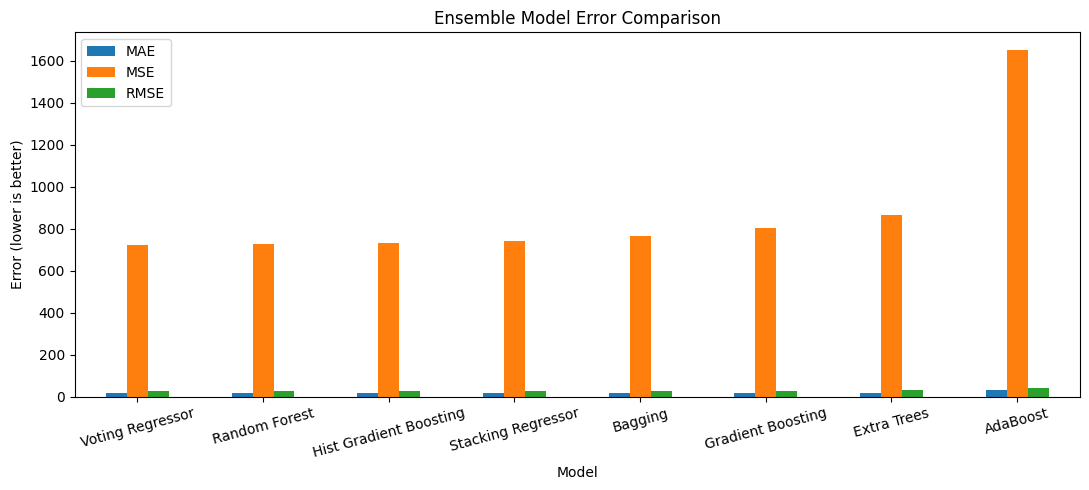

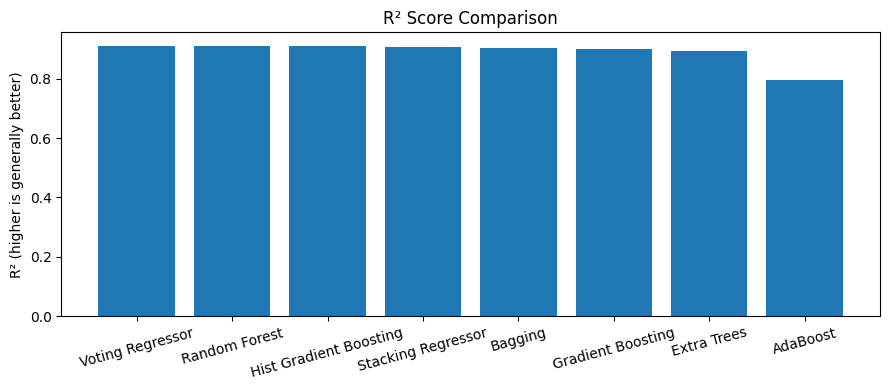

In [6]:
ax = results_df.set_index("Model")[["MAE", "MSE", "RMSE"]].plot(
    kind="bar", figsize=(11, 5), rot=15
)
ax.set_title("Ensemble Model Error Comparison")
ax.set_ylabel("Error (lower is better)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R² Score Comparison")
plt.ylabel("R² (higher is generally better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 7. Actual vs Predicted AQI

The following graph compares actual AQI with predictions from the best-performing ensemble model. Points closer to the diagonal line indicate more accurate predictions.


Best model by RMSE: Voting Regressor


,Best model result
Model,Voting Regressor
MAE,16.658149
MSE,720.144182
RMSE,26.835502
R2 Score,0.911062


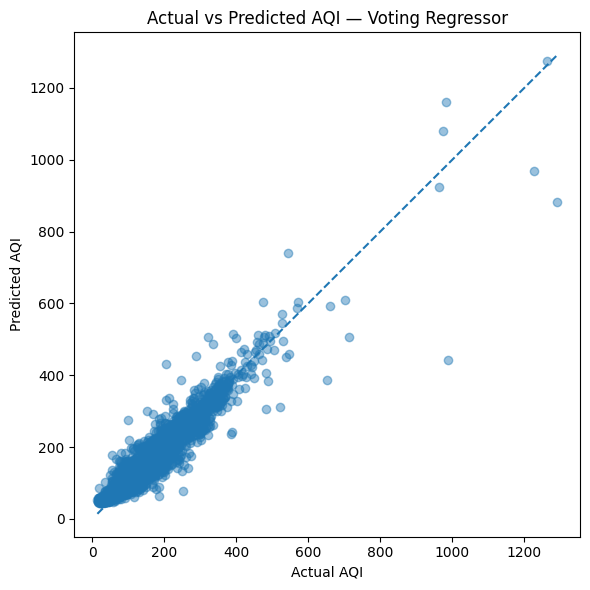

In [7]:
best_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_name]
best_row = results_df.iloc[0]

print("Best model by RMSE:", best_name)
display(best_row.to_frame("Best model result"))

low = min(float(y_test.min()), float(np.min(best_pred)))
high = max(float(y_test.max()), float(np.max(best_pred)))
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.45)
plt.plot([low, high], [low, high], linestyle="--")
plt.title(f"Actual vs Predicted AQI — {best_name}")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.tight_layout()
plt.show()


## 8. Result Interpretation

Discuss:
- Which model has the lowest RMSE?
- Which model has the highest R²?
- How large are the MAE and RMSE in AQI units?
- How closely do the predictions follow the diagonal in the actual-versus-predicted graph?
- What limitations remain (missing pollutant readings, city coverage, changing pollution patterns)?

**Conclusion template:** “The ensemble models were trained to estimate AQI using pollutant and city/date features. Their performance was compared using MAE, MSE, RMSE and R² on a chronological test set. The model with the lowest test RMSE was ______, with RMSE ______ and R² ______. This suggests ______.”


In [8]:
print(f"Best model: {best_name}")
print(f"MAE: {best_row['MAE']:.3f}")
print(f"MSE: {best_row['MSE']:.3f}")
print(f"RMSE: {best_row['RMSE']:.3f}")
print(f"R2: {best_row['R2 Score']:.3f}")

print(
    f"On the chronological test set, {best_name} achieved the lowest RMSE "
    f"({best_row['RMSE']:.3f}) among the evaluated ensemble models."
)


Best model: Voting Regressor
MAE: 16.658
MSE: 720.144
RMSE: 26.836
R2: 0.911
On the chronological test set, Voting Regressor achieved the lowest RMSE (26.836) among the evaluated ensemble models.
